> Runs on its own: all the code is inside this notebook (copied from `src/`), so you can open just this file, e.g. in Colab, or run it from the cloned repo (Anaconda Jupyter on Windows/Linux/macOS, or Colab after cloning https://github.com/Rishabh-bgp/multi-agent-turbine-fleet-chief-of-staff). Install dependencies once with `%pip install -r requirements.txt` (or `%pip install -r ../requirements.txt` from `notebooks/`). The data cell finds the committed synthetic CSV, downloads it from GitHub, or regenerates it.

# Walkthrough: forecasting agent + one multi-agent planning cycle
Simplified version of `src/simulate.py`. Agents are deterministic Python (no LLM). Reference implementation of my paper, rebuilt on synthetic data; numbers will differ from the published ones.

## Please read first: what these numbers mean
This notebook is a **short teaching demo on synthetic (computer-generated) data**. It is **not** a reproduction of the paper's results, and the numbers below should not be compared with the paper's tables.

- The data in `data/` is made up by a seeded generator. The real SCADA data is confidential and is not in this repository.
- The model trains for only a few minutes on a CPU, so it is much smaller and less tuned than in the paper.
- The model predicts the **change from the last reading** (the *persistence* forecast, "next hour = this hour") and adds it back. A fair test of any wind forecaster is whether it beats persistence, so both are printed side by side, with the real numbers, whatever they are.

In [1]:
# install anything missing (Colab already has most of these)
import importlib.util, subprocess, sys
missing = [m for m in ['numpy','pandas','torch','matplotlib','sklearn'] if importlib.util.find_spec(m) is None]
if missing: subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q'] + [{'sklearn': 'scikit-learn'}.get(m, m) for m in missing])
import os, urllib.request
from pathlib import Path
os.environ.setdefault('OMP_NUM_THREADS', '2')
REPO = 'multi-agent-turbine-fleet-chief-of-staff'

def find_csv(name):
    """../data/synthetic -> data/synthetic -> GitHub raw URL -> regenerate with the seeded generator."""
    for p in [Path.cwd().parent / 'data' / 'synthetic' / name, Path.cwd() / 'data' / 'synthetic' / name]:
        if p.exists(): return p
    out = Path.cwd() / 'data' / 'synthetic' / name; out.parent.mkdir(parents=True, exist_ok=True)
    try:
        urllib.request.urlretrieve(f'https://raw.githubusercontent.com/Rishabh-bgp/{REPO}/main/data/synthetic/{name}', out); return out
    except Exception as e:
        print('download failed, regenerating synthetic data:', e)
    if name == 'synthetic_sites.csv':
        synthetic_sites(n_hours=24 * 60, seed=0).to_csv(out, index=False)
    else:
        d = synthetic_scada(24 * 120, seed=0); d.index.name = 'timestamp'; d.to_csv(out)
    return out

import numpy as np, torch, matplotlib.pyplot as plt
torch.manual_seed(0); torch.set_num_threads(2)
EPOCHS = 25   # short CPU demo (the full script in src/ trains longer)
print('ready')

ready


## 0. The method's code
This cell holds the model, data and metric code, copied from `src/` so the notebook needs nothing else. You can skip reading it; the steps below use it.

In [2]:
# ===== from src/data.py =====
import numpy as np
import pandas as pd

ALIASES = {
    "wind_speed": ["wind_speed", "windspeed", "wind speed (m/s)", "ws", "wind_speed_ms"],
    "wind_direction": ["wind_direction", "wind direction (°)", "wd", "winddirection"],
    "temperature": ["temperature", "temp", "ambient_temperature"],
    "pressure": ["pressure", "pres"],
    "humidity": ["humidity", "rh"],
    "power": ["power", "lv activepower (kw)", "active_power", "power_kw"],
}

def load_scada_csv(path, freq="1h"):
    df = pd.read_csv(path)
    cols = {c.lower().strip(): c for c in df.columns}
    out = pd.DataFrame()
    tcol = next((cols[c] for c in cols if c in ("timestamp", "date/time", "datetime", "time", "date")), None)
    if tcol is None:
        raise ValueError("CSV needs a timestamp column")
    out["timestamp"] = pd.to_datetime(df[tcol], dayfirst=True, errors="coerce")
    for std, names in ALIASES.items():
        for n in names:
            if n in cols:
                out[std] = pd.to_numeric(df[cols[n]], errors="coerce")
                break
    if "wind_speed" not in out:
        raise ValueError("CSV needs a wind_speed column")
    out = out.dropna(subset=["timestamp"]).set_index("timestamp").sort_index()
    out = out.resample(freq).mean().interpolate(limit=6).dropna()
    return out

def synthetic_scada(n_hours=24 * 120, seed=0):
    """Synthetic hourly SCADA-like series: diurnal + seasonal cycle, AR(1) turbulence,
    occasional gust regimes, Weibull-like marginal. Purely for smoke tests."""
    rng = np.random.default_rng(seed)
    t = np.arange(n_hours)
    base = 7 + 1.5 * np.sin(2 * np.pi * t / 24 - 1.0) + 2.0 * np.sin(2 * np.pi * t / (24 * 365))
    ar = np.zeros(n_hours)
    regime = (np.sin(2 * np.pi * t / 240) + rng.normal(0, .3, n_hours)) > 0.8  # gusty spells
    for i in range(1, n_hours):
        ar[i] = 0.85 * ar[i - 1] + rng.normal(0, 0.6 + 0.9 * regime[i])
    ws = np.clip(base + ar, 0.2, None)
    wd = (200 + 40 * np.sin(2 * np.pi * t / 500) + rng.normal(0, 15, n_hours)) % 360
    temp = 28 + 4 * np.sin(2 * np.pi * t / 24 - 2) + rng.normal(0, .5, n_hours)
    pres = 1008 - 0.6 * ar + rng.normal(0, .4, n_hours)
    hum = np.clip(70 - 8 * np.sin(2 * np.pi * t / 24 - 2) + rng.normal(0, 3, n_hours), 10, 100)
    power = np.clip(3600 / (1 + np.exp(-(ws - 9) * 0.9)) * (ws > 3) * (ws < 25), 0, 3600)
    idx = pd.date_range("2018-01-01", periods=n_hours, freq="h")
    return pd.DataFrame(dict(wind_speed=ws, wind_direction=wd, temperature=temp, pressure=pres,
                             humidity=hum, power=power), index=idx)

def add_features(df):
    d = df.copy()
    h, doy = d.index.hour, d.index.dayofyear
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24)
    d["doy_sin"], d["doy_cos"] = np.sin(2 * np.pi * doy / 365), np.cos(2 * np.pi * doy / 365)
    if "wind_direction" in d:
        r = np.deg2rad(d.pop("wind_direction"))
        d["wd_sin"], d["wd_cos"] = np.sin(r), np.cos(r)
    roll = d["wind_speed"].rolling(6, min_periods=2)
    d["turb_intensity"] = (roll.std() / roll.mean().clip(lower=0.1)).fillna(0)
    d["ws_rate3h"] = d["wind_speed"].diff(3).fillna(0)
    return d

def make_windows(df, target="wind_speed", lookback=24, horizon=1):
    X, y = df.values.astype("float32"), df[target].values.astype("float32")
    xs, ys = [], []
    for i in range(lookback, len(df) - horizon + 1):
        xs.append(X[i - lookback:i]); ys.append(y[i + horizon - 1])
    return np.stack(xs), np.array(ys)

def chrono_split(n, val=0.15, test=0.15):
    a, b = int(n * (1 - val - test)), int(n * (1 - test))
    return slice(0, a), slice(a, b), slice(b, n)

class Scaler:
    def fit(self, X):
        self.m = X.reshape(-1, X.shape[-1]).mean(0); self.s = X.reshape(-1, X.shape[-1]).std(0) + 1e-6; return self
    def transform(self, X):
        return (X - self.m) / self.s


# ===== from src/metrics.py =====
import numpy as np

def regression_metrics(y, p, eps=0.5):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = y - p
    ss = ((y - y.mean()) ** 2).sum()
    return {"MAE": float(np.abs(e).mean()), "RMSE": float(np.sqrt((e ** 2).mean())),
            # MAPE skips near-calm samples (|y| < eps m/s) to avoid division blow-up
            "MAPE_%": float(100 * np.mean(np.abs(e[np.abs(y) >= eps] / y[np.abs(y) >= eps]))),
            "R2": float(1 - (e ** 2).sum() / ss)}


# ===== from src/trainutil.py =====
import numpy as np
import torch

def fit(model, Xtr, ytr, Xva, yva, epochs=15, lr=2e-3, bs=128, loss_fn=None, patience=4, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = loss_fn or torch.nn.MSELoss()
    Xtr, ytr = torch.tensor(Xtr), torch.tensor(ytr)
    Xva, yva = torch.tensor(Xva), torch.tensor(yva)
    best, state, wait = np.inf, None, 0
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xtr))
        for i in range(0, len(Xtr), bs):
            b = perm[i:i + bs]; opt.zero_grad()
            loss = loss_fn(model(Xtr[b]), ytr[b]); loss.backward(); opt.step()
        model.eval()
        with torch.no_grad():
            v = float(loss_fn(model(Xva), yva))
        if v < best:
            best, wait = v, 0; state = {k: t.clone() for k, t in model.state_dict().items()}
        else:
            wait += 1
            if wait >= patience: break
    model.load_state_dict(state); return model

def predict(model, X):
    model.eval()
    with torch.no_grad():
        out = model(torch.tensor(X))
    return out.numpy()


# ===== from src/forecaster.py =====
import torch
import torch.nn as nn

class CNNBiLSTMAttention(nn.Module):
    def __init__(self, n_features, conv=32, hidden=32):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv1d(n_features, conv, 3, padding=1), nn.ReLU())
        self.lstm = nn.LSTM(conv, hidden, batch_first=True, bidirectional=True)
        self.att = nn.Linear(2 * hidden, 1); self.head = nn.Linear(2 * hidden, 1)

    def forward(self, x):
        h, _ = self.lstm(self.conv(x.transpose(1, 2)).transpose(1, 2))
        a = torch.softmax(self.att(h), 1)
        return self.head((a * h).sum(1)).squeeze(-1)

def power_curve(ws, rated_kw=2000.0, cut_in=3.0, rated=12.0, cut_out=25.0):
    import numpy as np
    ws = np.asarray(ws, float)
    p = np.where((ws >= cut_in) & (ws < rated), rated_kw * ((ws - cut_in) / (rated - cut_in)) ** 3, 0.0)
    return np.where((ws >= rated) & (ws < cut_out), rated_kw, p)


# ===== from src/agents/core.py =====
from dataclasses import dataclass, field, asdict
import json, time

@dataclass
class Message:
    sender: str
    kind: str
    payload: dict
    ts: float = field(default_factory=time.time)

class ContextBus:
    """Short-term blackboard for one planning cycle + append-only audit log."""
    def __init__(self):
        self.board, self.log = {}, []

    def post(self, msg: Message):
        self.board[msg.kind] = msg.payload; self.log.append(asdict(msg))

    def get(self, kind, default=None):
        return self.board.get(kind, default)

    def dump(self, path):
        json.dump(self.log, open(path, "w"), indent=1, default=str)

class Agent:
    name = "agent"

    def __init__(self, bus: ContextBus):
        self.bus = bus

    def emit(self, kind, payload):
        self.bus.post(Message(self.name, kind, payload)); return payload


# ===== from src/agents/retrieval.py =====
KNOWLEDGE = [
 "Gearbox oil temperature above 80 C for more than 2 hours: reduce power set-point and schedule an inspection.",
 "Main bearing vibration RMS above 7 mm/s (ISO 10816 zone D style limit): stop the turbine for inspection.",
 "Grid operator curtailment instructions must be followed within 15 minutes; log the instruction id.",
 "Forecast deviation beyond the permitted band attracts deviation-settlement charges; revise schedules early.",
 "Maintenance should be scheduled in forecast low-wind windows to minimize lost energy."
]

import re
from pathlib import Path
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

class Retriever:
    def __init__(self, folder=None):
        self.docs = list(KNOWLEDGE)  # the notes from knowledge/*.md, embedded so the notebook runs on its own
        self.v = TfidfVectorizer().fit(self.docs); self.M = self.v.transform(self.docs)

    def query(self, q, k=2):
        s = cosine_similarity(self.v.transform([q]), self.M)[0]
        return [self.docs[i] for i in s.argsort()[::-1][:k]]


# ===== from src/agents/specialists.py =====
import numpy as np

class ForecastingAgent(Agent):
    """Wraps a trained forecaster; emits per-turbine next-hour wind speed and power."""
    name = "forecasting"

    def __init__(self, bus, forecaster, power_curve):
        super().__init__(bus); self.f, self.pc = forecaster, power_curve

    def run(self, windows):
        ws = self.f(windows)
        return self.emit("forecast", {"wind_speed": ws.tolist(), "power_kw": self.pc(ws).tolist()})

class ScadaMonitoringAgent(Agent):
    """Rolling z-score anomaly detector on SCADA channels."""
    name = "scada_monitor"

    def __init__(self, bus, z=3.0):
        super().__init__(bus); self.z = z

    def run(self, history, current):     # history (T, N, C), current (N, C)
        mu, sd = history.mean(0), history.std(0) + 1e-6
        zs = np.abs((current - mu) / sd)
        return self.emit("anomalies", {"turbines": np.where((zs > self.z).any(1))[0].tolist(),
                                       "max_z": zs.max(1).round(2).tolist()})

class PredictiveMaintenanceAgent(Agent):
    """Threshold rules on vibration and gearbox temperature -> risk score and work orders (mock CMMS)."""
    name = "maintenance"

    def __init__(self, bus, retriever: Retriever, vib_limit=7.0, temp_limit=80.0):
        super().__init__(bus); self.r, self.vl, self.tl = retriever, vib_limit, temp_limit

    def run(self, vibration, gearbox_temp):
        risk = np.clip(np.maximum(vibration / self.vl, (gearbox_temp - 40) / (self.tl - 40)), 0, 1.5)
        orders = []
        for i in np.where(risk >= 0.9)[0]:
            q = "vibration stop inspection" if vibration[i] / self.vl >= (gearbox_temp[i] - 40) / (self.tl - 40) else "gearbox oil temperature"
            orders.append({"turbine": int(i), "risk": round(float(risk[i]), 3), "action": "derate_and_inspect" if risk[i] < 1 else "stop_and_inspect",
                           "evidence": self.r.query(q, k=1)})
        return self.emit("work_orders", {"risk": risk.round(3).tolist(), "orders": orders})

class GridTradingAgent(Agent):
    """Compares forecast fleet power with grid limit; proposes proportional curtailment."""
    name = "grid_trading"

    def run(self, forecast_kw, grid_limit_kw, unavailable):
        p = np.array(forecast_kw, float); p[list(unavailable)] = 0
        total = p.sum(); factor = min(1.0, grid_limit_kw / total) if total > 0 else 1.0
        return self.emit("dispatch", {"setpoints_kw": (p * factor).round(1).tolist(), "curtail_factor": round(factor, 4),
                                      "scheduled_kw": float((p * factor).sum())})

class ReportingHITLAgent(Agent):
    """Builds the action bundle and holds it for human approval (approver is a callable)."""
    name = "reporting_hitl"

    def __init__(self, bus, approver):
        super().__init__(bus); self.approver = approver

    def run(self, bundle):
        approved = bool(self.approver(bundle))
        return self.emit("approval", {"approved": approved, "bundle": bundle})


# ===== from src/agents/orchestrator.py =====
class OrchestratorAgent:
    """Chief of staff: runs one planning cycle, resolves conflicts (maintenance vs. dispatch),
    and is the only component allowed to commit approved actions."""
    name = "orchestrator"

    def __init__(self, forecaster, power_curve, approver, knowledge=None):
        self.bus = ContextBus()
        r = Retriever(knowledge)
        self.fc = ForecastingAgent(self.bus, forecaster, power_curve)
        self.mon = ScadaMonitoringAgent(self.bus)
        self.pm = PredictiveMaintenanceAgent(self.bus, r)
        self.grid = GridTradingAgent(self.bus)
        self.hitl = ReportingHITLAgent(self.bus, approver)
        self.committed = []

    def cycle(self, windows, history, current, vibration, gearbox_temp, grid_limit_kw):
        f = self.fc.run(windows)
        an = self.mon.run(history, current)
        wo = self.pm.run(vibration, gearbox_temp)
        stopped = {o["turbine"] for o in wo["orders"] if o["action"] == "stop_and_inspect"}
        # conflict resolution: turbines under stop orders are unavailable to dispatch
        d = self.grid.run(f["power_kw"], grid_limit_kw, stopped)
        bundle = {"forecast": f, "anomalies": an, "work_orders": wo["orders"], "dispatch": d}
        ap = self.hitl.run(bundle)
        if ap["approved"]:
            self.committed.append(bundle)
        return bundle, ap["approved"]

## 1. Load the committed synthetic SCADA-style CSV
`data/synthetic/synthetic_scada.csv` is **synthetic** (seeded generator `scripts/make_synthetic.py`), not the confidential original SCADA data.

In [3]:
raw = load_scada_csv(find_csv('synthetic_scada.csv'))
raw.head()

,wind_speed,wind_direction,temperature,pressure,humidity,power
timestamp,,,,,,
2018-01-01 00:00:00,5.737794,223.408447,23.940016,1008.144888,79.291828,181.450999
2018-01-01 01:00:00,5.311578,203.414522,25.093541,1008.083422,78.237979,125.660019
2018-01-01 02:00:00,6.098380,187.419159,23.755674,1008.513628,75.607545,246.256732
2018-01-01 03:00:00,5.912926,207.694372,24.992387,1007.578456,73.548041,210.616083
2018-01-01 04:00:00,5.666016,211.785966,24.673154,1008.536566,75.529499,170.637901


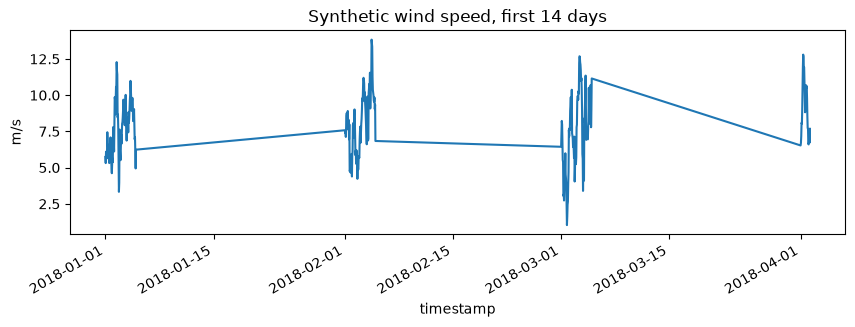

In [4]:
raw['wind_speed'].iloc[:24*14].plot(figsize=(10,3), title='Synthetic wind speed, first 14 days'); plt.ylabel('m/s'); plt.show()

## 2. Train the forecasting agent's small CNN-BiLSTM-Attention briefly

In [5]:
df = add_features(raw); X, y = make_windows(df, lookback=24); wi = list(df.columns).index('wind_speed')
tr, va, te = chrono_split(len(X)); sc = Scaler().fit(X[tr]); Xs = sc.transform(X).astype('float32'); last = X[:, -1, wi]; d = y - last   # target: change from the last reading (persistence)
ym, ys = d[tr].mean(), d[tr].std()
m = fit(CNNBiLSTMAttention(X.shape[2]), Xs[tr], ((d[tr]-ym)/ys).astype('float32'), Xs[va], ((d[va]-ym)/ys).astype('float32'), epochs=EPOCHS, patience=6)
pred = last[te] + predict(m, Xs[te])*ys + ym   # add the predicted change back
print('forecast   ', regression_metrics(y[te], pred))
print('persistence', regression_metrics(y[te], X[te][:, -1, wi]))

/tmp/ipykernel_204128/3512391076.py:55: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  h, doy = d.index.hour, d.index.dayofyear


forecast    {'MAE': 0.7304058816697863, 'RMSE': 1.006055633042263, 'MAPE_%': 9.44248835669754, 'R2': 0.820667056495185}
persistence {'MAE': 0.7786463048723009, 'RMSE': 1.0788346983033934, 'MAPE_%': 10.084407356304313, 'R2': 0.7937823207879058}


### Result in plain words
- **1 h ahead:** model RMSE 1.006 m/s vs persistence 1.079 m/s (R² 0.821 vs 0.794). The model beats persistence here.

These numbers come from about a minute of training on synthetic data. They show that the code works and learns something useful beyond "next hour = this hour"; they are not the paper's results.

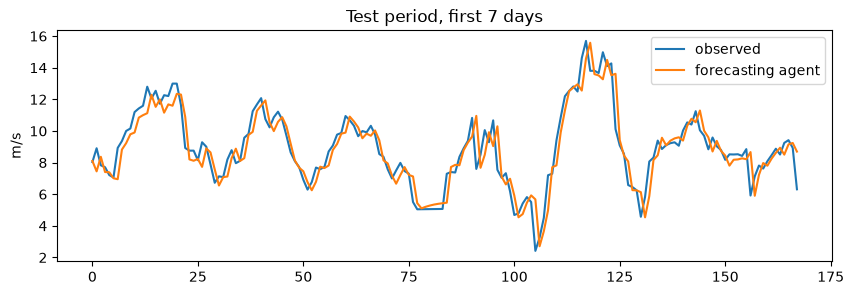

In [6]:
plt.figure(figsize=(10,3)); plt.plot(y[te][:168], label='observed'); plt.plot(pred[:168], label='forecasting agent'); plt.legend(); plt.ylabel('m/s'); plt.title('Test period, first 7 days'); plt.show()

## 3. One orchestrated cycle for a 4-turbine fleet (turbine 2 is degrading)
The orchestrator runs forecasting → SCADA monitor → maintenance → grid/trading → human approval gate.

In [7]:
forecaster = lambda Wd: Wd[:, -1, wi] + predict(m, sc.transform(Wd).astype('float32'))*ys + ym
orch = OrchestratorAgent(forecaster, power_curve, approver=lambda b: True)
win = np.stack([X[te][0]]*4); vib = np.array([2.5,3.0,7.5,2.8]); temp = np.array([58,60,84,57.])
hist = np.random.default_rng(0).normal([3,58],[0.5,2],(24,4,2))
bundle, ok = orch.cycle(win, hist, np.stack([vib,temp],-1), vib, temp, grid_limit_kw=5000)
print('approved:', ok); bundle['work_orders'], bundle['dispatch']

approved: True


([{'turbine': 2,
   'risk': 1.1,
   'action': 'stop_and_inspect',
   'evidence': ['Gearbox oil temperature above 80 C for more than 2 hours: reduce power set-point and schedule an inspection.']}],
 {'setpoints_kw': [365.1, 365.1, 0.0, 365.1],
  'curtail_factor': 1.0,
  'scheduled_kw': 1095.3771748846784})